In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score

# loading dataset
df = pd.read_csv(r"C:\Users\HP\Downloads\Heart.csv")
print("--- 1. DATASET OVERVIEW ---")
print(f"Total Rows (Patients): {df.shape[0]}, Total Features: {df.shape[1]}")
df.head()

--- 1. DATASET OVERVIEW ---
Total Rows (Patients): 303, Total Features: 15


,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


In [3]:
print("--- 2. EXPLORATORY DATA ANALYSIS (EDA) ---")
print("\n[A] Checking for missing values in any column:")
print(df.isnull().sum())

print("\n[B] Statistical Analysis of Numerical features:")
df.describe().T

--- 2. EXPLORATORY DATA ANALYSIS (EDA) ---

[A] Checking for missing values in any column:
Unnamed: 0    0
Age           0
Sex           0
ChestPain     0
RestBP        0
Chol          0
Fbs           0
RestECG       0
MaxHR         0
ExAng         0
Oldpeak       0
Slope         0
Ca            4
Thal          2
AHD           0
dtype: int64

[B] Statistical Analysis of Numerical features:


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,303.0,152.000000,87.612784,1.0,76.5,152.0,227.5,303.0
Age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
Sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
RestBP,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
Chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
Fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
RestECG,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
MaxHR,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
ExAng,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
Oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


--- EDA: DISTRIBUTION OF TARGET VARIABLE ('AHD') ---
AHD
No     164
Yes    139
Name: count, dtype: int64


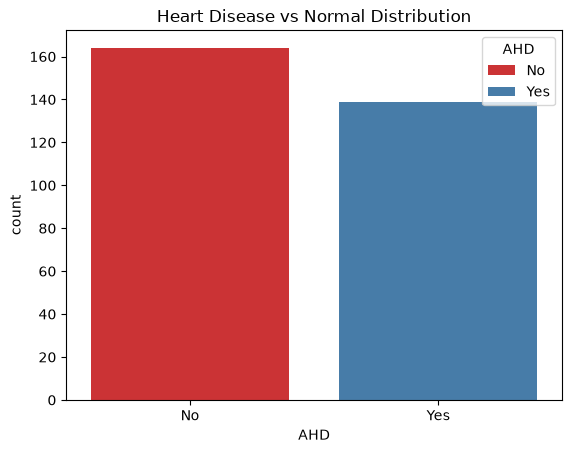

In [4]:
# Automatically identifying target column
target_col = 'target' if 'target' in df.columns else df.columns[-1]

print(f"--- EDA: DISTRIBUTION OF TARGET VARIABLE ('{target_col}') ---")
print(df[target_col].value_counts())

# Target Column ka quick plot banana (Visual EDA)
sns.countplot(x=target_col, data=df,palette='Set1',legend=True,hue=target_col)
plt.title("Heart Disease vs Normal Distribution")
plt.show()

In [6]:
print("--- 3. DATA PREPROCESSING ---")

# Separate inputs (X) and target outputs (y)
X = df.drop(columns=[target_col])
y = df[target_col]

# Convert text columns to numbers (One-Hot Encoding)
X = pd.get_dummies(X, drop_first=True)

# Splitting into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Scaling (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data preprocessing, splitting, and scaling completed!")
print(f"Training shapes: X_train: {X_train_scaled.shape}, y_train: {y_train.shape}")


--- 3. DATA PREPROCESSING ---
Data preprocessing, splitting, and scaling completed!
Training shapes: X_train: (242, 17), y_train: (242,)


In [7]:
print("--- 4. SUPERVISED ML IMPLEMENTATION & EVALUATION ---")

# Training the Supervised Algorithm
model = RandomForestClassifier(random_state=42)
model.fit(X_train_scaled, y_train)
print("Supervised Model trained successfully!")

# Making Predictions
y_pred = model.predict(X_test_scaled)

# Final Accuracy Check
accuracy = accuracy_score(y_test, y_pred)
print(f"\n🎉 Overall Model Accuracy: {accuracy * 100:.2f}%")

print("\nDetailed Performance Matrix (Classification Report):")
print(classification_report(y_test, y_pred))

--- 4. SUPERVISED ML IMPLEMENTATION & EVALUATION ---
Supervised Model trained successfully!

🎉 Overall Model Accuracy: 88.52%

Detailed Performance Matrix (Classification Report):
              precision    recall  f1-score   support

          No       0.84      0.93      0.89        29
         Yes       0.93      0.84      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



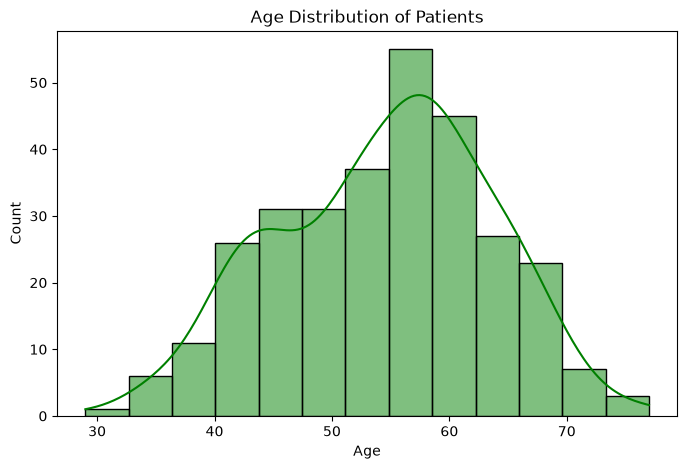

In [17]:
plt.figure(figsize=(8, 5))#width,height
sns.histplot(df['Age'], kde=True, color='green')#kernel density estimation for smooth curve
plt.title("Age Distribution of Patients")
plt.show()


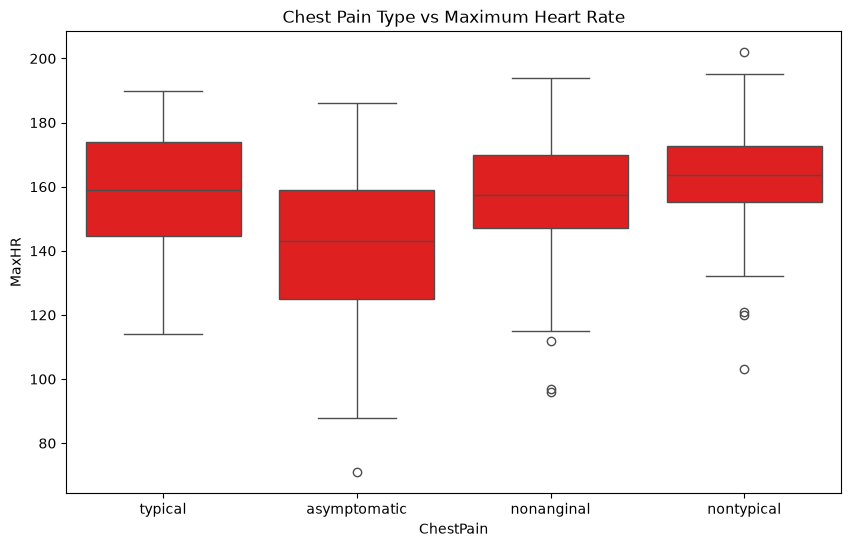

                min     25%    50%    max
ChestPain                                
asymptomatic   71.0  125.00  143.0  186.0
nonanginal     96.0  147.25  157.5  194.0
nontypical    103.0  155.25  163.5  202.0
typical       114.0  144.50  159.0  190.0


In [19]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='ChestPain', y='MaxHR', data=df,color='Red')
plt.title("Chest Pain Type vs Maximum Heart Rate")
plt.show()
# According to chestpain summary of MaxHeartRate
exact_stats = df.groupby('ChestPain')['MaxHR'].describe()
print(exact_stats[['min', '25%', '50%', 'max']])

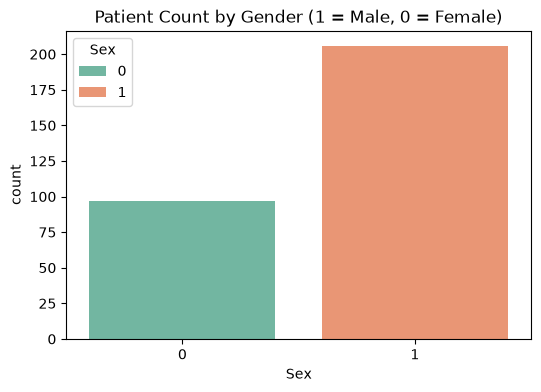

In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Sex', data=df, palette='Set2',hue='Sex',legend=True)
plt.title("Patient Count by Gender (1 = Male, 0 = Female)")
plt.show()